In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load CSV
awards_players = pd.read_csv("../basketballPlayoffs/awards_players.csv")

In [34]:
# Initial Inspection
#print(awards_players.head())
#print(awards_players.info())
#print(awards_players.describe(include='all'))

# Distribution of awards
print("Distribution of awards:")
print(awards_players['award'].value_counts())
print()


Distribution of awards:
award
Coach of the Year                         10
Defensive Player of the Year              10
Most Valuable Player                      10
Rookie of the Year                        10
WNBA Finals Most Valuable Player          10
WNBA All-Decade Team                      10
Kim Perrot Sportsmanship Award             9
Most Improved Player                       9
All-Star Game Most Valuable Player         8
WNBA All Decade Team Honorable Mention     5
Sixth Woman of the Year                    3
Kim Perrot Sportsmanship                   1
Name: count, dtype: int64



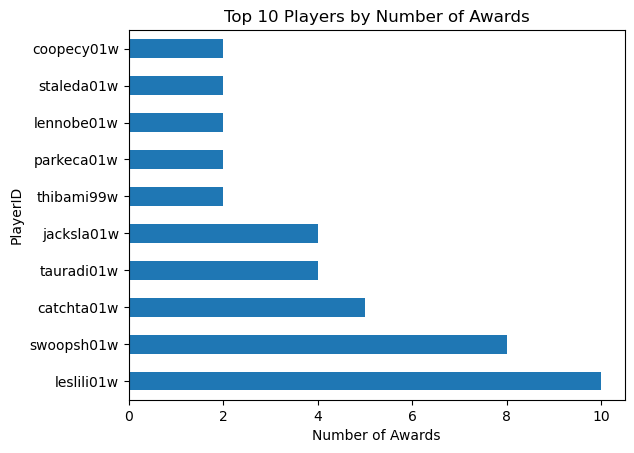

In [35]:
# Load CSV
awards_players_cleaned = pd.read_csv("../cleaned_datasets/awards_players_cleaned.csv")

# Awards by player
top_players = awards_players_cleaned['playerID'].value_counts().head(10)
top_players.plot(kind='barh', title='Top 10 Players by Number of Awards')
plt.xlabel('Number of Awards')
plt.ylabel('PlayerID')
plt.show()
print()

In [36]:
# Multi-Award Players
print("Multi-Award Players:")
multi_award_players = awards_players_cleaned.groupby('playerID').filter(lambda x: len(x) > 1)
print(multi_award_players)
print()

Multi-Award Players:
      playerID                                   award  year
0   thompti01w      All-Star Game Most Valuable Player     1
1   leslili01w      All-Star Game Most Valuable Player     2
2   leslili01w      All-Star Game Most Valuable Player     3
4   swoopsh01w      All-Star Game Most Valuable Player     6
6    fordch01w      All-Star Game Most Valuable Player     8
9   hugheda99w                       Coach of the Year     2
12  mcconsu01w                       Coach of the Year     5
14  thibami99w                       Coach of the Year     7
15  hugheda99w                       Coach of the Year     8
16  thibami99w                       Coach of the Year     9
18  swoopsh01w            Defensive Player of the Year     1
20  swoopsh01w            Defensive Player of the Year     3
21  swoopsh01w            Defensive Player of the Year     4
22  leslili01w            Defensive Player of the Year     5
23  catchta01w            Defensive Player of the Year     6
24 

In [37]:
# Find the most awarded player for each type of award

# Step 1: Count the number of times each player won each award
award_counts = awards_players_cleaned.groupby(['award', 'playerID']).size().reset_index(name='award_count')

# Step 2: Find the maximum award count for each award
max_award_counts = award_counts.groupby('award')['award_count'].transform(max)

# Step 3: Filter the DataFrame to include only rows where the player's count matches the maximum for that award
most_awarded_players = award_counts[award_counts['award_count'] == max_award_counts]

# Step 4: Sort and reset index for a clean display
most_awarded_players = most_awarded_players.sort_values(by=['award', 'playerID']).reset_index(drop=True)

# Display the result
print(most_awarded_players)

                                     award    playerID  award_count
0       All-Star Game Most Valuable Player  leslili01w            2
1                        Coach of the Year  hugheda99w            2
2                        Coach of the Year  thibami99w            2
3             Defensive Player of the Year  catchta01w            3
4             Defensive Player of the Year  swoopsh01w            3
5           Kim Perrot Sportsmanship Award  beviltu01w            1
6           Kim Perrot Sportsmanship Award  campbed01w            1
7           Kim Perrot Sportsmanship Award  edwarte01w            1
8           Kim Perrot Sportsmanship Award  gilloje01w            1
9           Kim Perrot Sportsmanship Award  johnsvi01w            1
10          Kim Perrot Sportsmanship Award  lawsoka01w            1
11          Kim Perrot Sportsmanship Award  mcconsu01w            1
12          Kim Perrot Sportsmanship Award  mcwilta01w            1
13          Kim Perrot Sportsmanship Award  stal